### Problem Defination:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

### Connect to MySQL Database

In [2]:
import mysql.connector

conn = mysql.connector.connect(
    host="18.136.157.135",
    port=3306,
    user="dm_team1",
    password="DM!$Team&279@20!",
    database="project_banking"
)

#### Load Tables

In [3]:
account = pd.read_sql("SELECT * FROM Cust_Account", conn)
enquiry = pd.read_sql("SELECT * FROM Cust_Enquiry", conn)
demo = pd.read_sql("SELECT * FROM Cust_Demographics", conn)

### Basic Checks

In [4]:
print(account.shape)
print(enquiry.shape)
print(demo.shape)

(186329, 21)
(413188, 6)
(23896, 83)


In [5]:
account.head()

,dt_opened,customer_no,upload_dt,acct_type,owner_indic,opened_dt,last_paymt_dt,closed_dt,reporting_dt,high_credit_amt,...,amt_past_due,paymenthistory1,paymenthistory2,paymt_str_dt,paymt_end_dt,creditlimit,cashlimit,rateofinterest,paymentfrequency,actualpaymentamount
0,10-Nov-15,12265,20-Oct-15,6,1,09-Jun-13,30-Jun-14,05-Jul-14,30-Sep-15,20900,...,,"""""""STDSTDSTDXXXXXXXXXXXXXXXSTDXXXXXXXXXXXXXXXS...",,01-Sep-15,01-Jul-14,,,,,
1,10-Nov-15,12265,20-Oct-15,10,1,25-May-12,06-Sep-15,,03-Oct-15,16201,...,,"""""""0000000000000000000000000000000000000000000...","""""""000000000000000000000000000XXX0000000000000...",01-Oct-15,01-Nov-12,14000,1400,,3,5603
2,10-Nov-15,12265,20-Oct-15,10,1,22-Mar-12,31-Aug-15,,30-Sep-15,41028,...,,"""""""0000000000000000000000000000000000000000000...","""""""0000000000000000000000000000000000000000000...",01-Sep-15,01-Oct-12,,,,,
3,20-Jul-15,15606,09-Jul-15,10,1,13-Jan-06,,26-Jul-07,31-Jan-09,93473,...,,"""""""1200900600600600300000000000000000000000000...",,01-Jul-07,01-Feb-06,,,,,
4,20-Jul-15,15606,09-Jul-15,6,1,18-Jan-15,05-May-15,,31-May-15,20250,...,,"""""""000000000000000""""""",,01-May-15,01-Jan-15,,,,,


In [6]:
account.columns

Index(['dt_opened', 'customer_no', 'upload_dt', 'acct_type', 'owner_indic',
       'opened_dt', 'last_paymt_dt', 'closed_dt', 'reporting_dt',
       'high_credit_amt', 'cur_balance_amt', 'amt_past_due', 'paymenthistory1',
       'paymenthistory2', 'paymt_str_dt', 'paymt_end_dt', 'creditlimit',
       'cashlimit', 'rateofinterest', 'paymentfrequency',
       'actualpaymentamount'],
      dtype='object')

In [7]:
enquiry.head()

,dt_opened,customer_no,upload_dt,enquiry_dt,enq_purpose,enq_amt
0,18-Apr-15,1,21-Apr-15,19-Dec-14,2,3500000
1,18-Apr-15,1,21-Apr-15,05-Mar-14,5,500000
2,18-Apr-15,1,21-Apr-15,05-Mar-14,0,50000
3,18-Apr-15,1,21-Apr-15,22-Feb-14,10,50000
4,18-Apr-15,1,21-Apr-15,11-Jun-13,10,1000


In [8]:
demo.head()

,dt_opened,customer_no,entry_time,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,...,feature_71,feature_72,feature_73,feature_74,feature_75,feature_76,feature_77,feature_78,feature_79,Bad_label
0,18-Apr-15,1,13-Apr-15,Insignia,13-Apr-15,650,2,Card Setup,14,500000,...,21,R,,,0000-00-00,0,98332XXXXX,1,N,0
1,21-Apr-15,2,21-Apr-15,Insignia,21-Apr-15,760,1,Card Setup,14,1200000,...,17,R,,,0000-00-00,0,99455XXXXX,1,N,0
2,22-Apr-15,3,21-Apr-15,Insignia,21-Apr-15,774,1,Card Setup,14,700000,...,17,R,,,0000-00-00,0,98456XXXXX,1,N,0
3,25-Apr-15,4,15-Apr-15,Insignia,20-Apr-15,770,1,Card Setup,14,500000,...,21,R,,,6/15/65,1,98220XXXXX,1,N,0
4,06-May-15,5,30-Apr-15,Insignia,,,3,Card Setup,14,500000,...,13,R,,,0000-00-00,0,98111XXXXX,1,N,0


In [9]:
demo.columns

Index(['dt_opened', 'customer_no', 'entry_time', 'feature_1', 'feature_2',
       'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7',
       'feature_8', 'feature_9', 'feature_10', 'feature_11', 'feature_12',
       'feature_13', 'feature_14', 'feature_15', 'feature_16', 'feature_17',
       'feature_18', 'feature_19', 'feature_20', 'feature_21', 'feature_22',
       'feature_23', 'feature_24', 'feature_25', 'feature_26', 'feature_27',
       'feature_28', 'feature_29', 'feature_30', 'feature_31', 'feature_32',
       'feature_33', 'feature_34', 'feature_35', 'feature_36', 'feature_37',
       'feature_38', 'feature_39', 'feature_40', 'feature_41', 'feature_42',
       'feature_43', 'feature_44', 'feature_45', 'feature_46', 'feature_47',
       'feature_48', 'feature_49', 'feature_50', 'feature_51', 'feature_52',
       'feature_53', 'feature_54', 'feature_55', 'feature_56', 'feature_57',
       'feature_58', 'feature_59', 'feature_60', 'feature_61', 'feature_62',
       '

### Data Cleaning

##### Check Missing values

In [10]:
account.isnull().sum()

dt_opened              0
customer_no            0
upload_dt              0
acct_type              0
owner_indic            0
opened_dt              0
last_paymt_dt          0
closed_dt              0
reporting_dt           0
high_credit_amt        0
cur_balance_amt        0
amt_past_due           0
paymenthistory1        0
paymenthistory2        0
paymt_str_dt           0
paymt_end_dt           0
creditlimit            0
cashlimit              0
rateofinterest         0
paymentfrequency       0
actualpaymentamount    0
dtype: int64

In [11]:
enquiry.isnull().sum()

dt_opened      0
customer_no    0
upload_dt      0
enquiry_dt     0
enq_purpose    0
enq_amt        0
dtype: int64

In [12]:
demo.isnull().sum()

dt_opened      0
customer_no    0
entry_time     0
feature_1      0
feature_2      0
              ..
feature_76     0
feature_77     0
feature_78     0
feature_79     0
Bad_label      0
Length: 83, dtype: int64

##### Converting Date Columns

In [13]:
date_cols_account = ['opened_dt', 'last_paymt_dt', 'closed_dt', 'reporting_dt']
for col in date_cols_account:
    account[col] = pd.to_datetime(account[col], errors='coerce')

enquiry['enquiry_dt'] = pd.to_datetime(enquiry['enquiry_dt'], errors='coerce')

#### EDA

###### Target Distribution

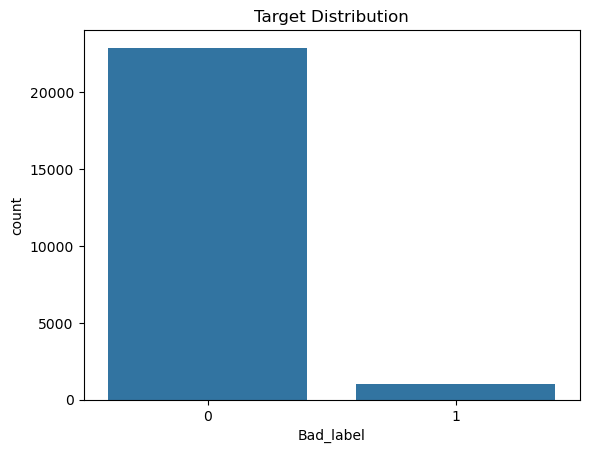

In [46]:
sns.countplot(x='Bad_label', data=df)
plt.title("Target Distribution")
plt.show()

###### Enquiries vs Target

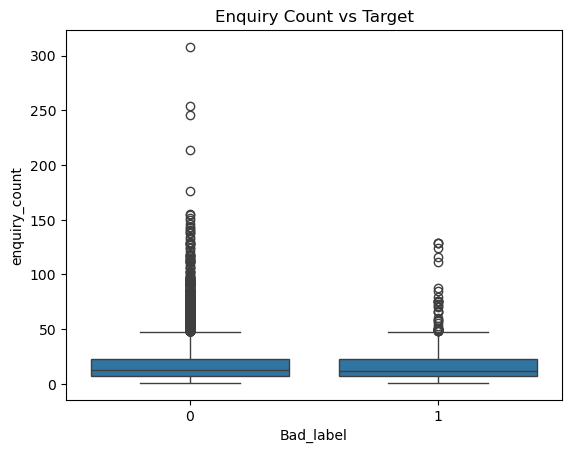

In [44]:
sns.boxplot(x='Bad_label', y='enquiry_count', data=df)
plt.title("Enquiry Count vs Target")
plt.show()

##### Distribution Plot

In [57]:
account_agg['overall_utilization'] = account_agg['overall_utilization'].clip(0, 5)

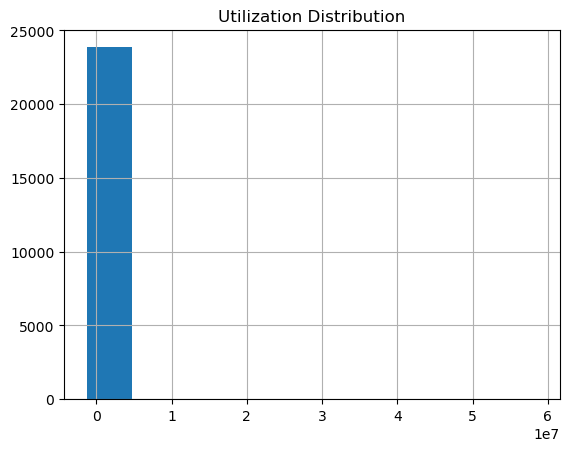

In [58]:
df['overall_utilization'].hist()
plt.title("Utilization Distribution")
plt.show()

##### Correlation HeatMap 

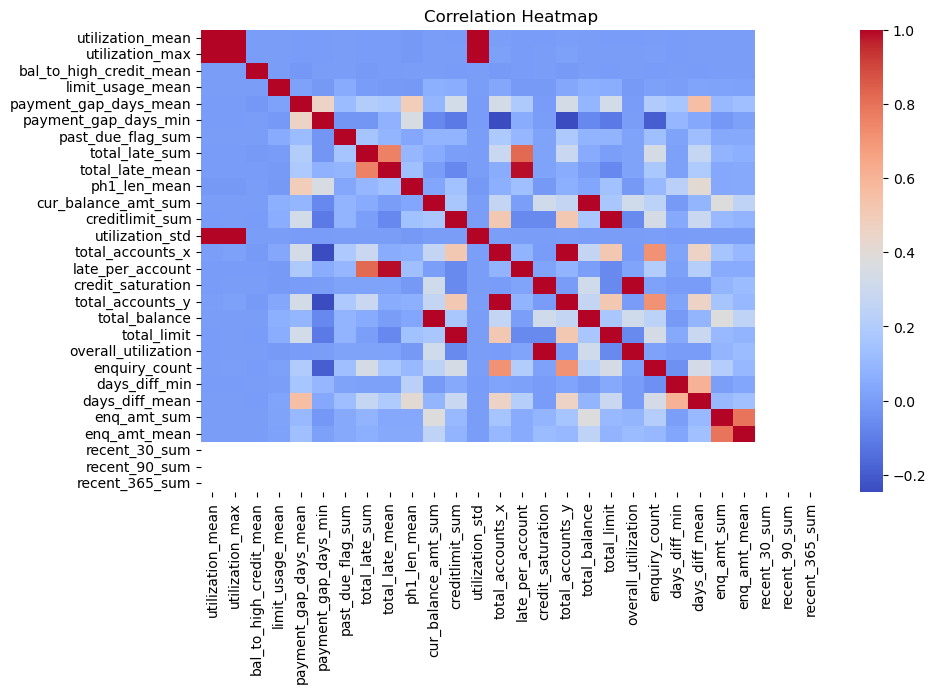

In [48]:
corr = df.select_dtypes(include=['number']).corr()

plt.figure(figsize=(10,6))
sns.heatmap(corr, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

##### Creating Features

###### Convert Numerics

In [14]:
account['cur_balance_amt'] = pd.to_numeric(account['cur_balance_amt'], errors='coerce')
account['creditlimit'] = pd.to_numeric(account['creditlimit'], errors='coerce')
account['amt_past_due'] = pd.to_numeric(account['amt_past_due'], errors='coerce')
account['high_credit_amt'] = pd.to_numeric(account['high_credit_amt'], errors='coerce')

###### Features

In [15]:
account['utilization'] = account['cur_balance_amt'] / account['creditlimit']
account['bal_to_high_credit'] = account['cur_balance_amt'] / account['high_credit_amt']
account['limit_usage'] = account['creditlimit'] / (account['high_credit_amt'] + 1)

account['payment_gap_days'] = (account['last_paymt_dt'] - account['opened_dt']).dt.days
account['past_due_flag'] = (account['amt_past_due'] > 0).astype(int)

account['total_late'] = (
    account['paymenthistory1'].astype(str).apply(lambda x: sum(int(i) for i in x if i.isdigit())) +
    account['paymenthistory2'].astype(str).apply(lambda x: sum(int(i) for i in x if i.isdigit()))
)

##### Payment History Features

In [16]:
account['ph1_len'] = account['paymenthistory1'].astype(str).apply(len)
account['ph2_len'] = account['paymenthistory2'].astype(str).apply(len)

account['ph1_late_count'] = account['paymenthistory1'].astype(str).str.count('1')
account['ph2_late_count'] = account['paymenthistory2'].astype(str).str.count('1')

account['total_late'] = account['ph1_late_count'] + account['ph2_late_count']

account['total_late'] = (
    account['paymenthistory1'].astype(str).apply(lambda x: sum(int(i) for i in x if i.isdigit())) +
    account['paymenthistory2'].astype(str).apply(lambda x: sum(int(i) for i in x if i.isdigit()))
)

###### Handle inf

In [17]:
account.replace([np.inf, -np.inf], 0, inplace=True)

In [18]:
enquiry['enq_amt'] = pd.to_numeric(enquiry['enq_amt'], errors='coerce')

##### Aggregation

In [19]:
account_agg = account.groupby('customer_no').agg({
    'utilization': ['mean', 'max'],
    'bal_to_high_credit': ['mean'],
    'limit_usage': ['mean'],
    'payment_gap_days': ['mean', 'min'],
    'past_due_flag': ['sum'],
    'total_late': ['sum', 'mean'],
    'ph1_len': ['mean'],

    'cur_balance_amt': ['sum'],
    'creditlimit': ['sum']
})

In [20]:
account_agg.columns = ['_'.join(col) for col in account_agg.columns]
account_agg = account_agg.reset_index()

In [21]:
# Account Diversity
account_agg['utilization_std'] = (account.groupby('customer_no')['utilization'].std().values)

# Total accounts per customer
account_agg['total_accounts'] = (account.groupby('customer_no').size().values)

# Delinquency Intensity
account_agg['late_per_account'] = (account_agg['total_late_sum'] /(account_agg['total_accounts'] + 1))

# Credit Saturation
account_agg['credit_saturation'] = (account_agg['cur_balance_amt_sum'] /(account_agg['creditlimit_sum'] + 1))

##### CUSTOMER-LEVEL FEATURES

In [22]:
# total accounts
account_count = account.groupby('customer_no').size().reset_index(name='total_accounts')

# total balance
total_balance = account.groupby('customer_no')['cur_balance_amt'].sum().reset_index(name='total_balance')

# total limit
total_limit = account.groupby('customer_no')['creditlimit'].sum().reset_index(name='total_limit')

# merge into account_agg
account_agg = account_agg.merge(account_count, on='customer_no', how='left')
account_agg = account_agg.merge(total_balance, on='customer_no', how='left')
account_agg = account_agg.merge(total_limit, on='customer_no', how='left')

# strongest feature
account_agg['overall_utilization'] = account_agg['total_balance'] / (account_agg['total_limit'] + 1)

In [23]:
from datetime import datetime

today = datetime.now()

# create days_diff
enquiry['days_diff'] = (today - enquiry['enquiry_dt']).dt.days

# create recent features
enquiry['recent_30'] = (enquiry['days_diff'] <= 30).astype(int)
enquiry['recent_90'] = (enquiry['days_diff'] <= 90).astype(int)
enquiry['recent_365'] = (enquiry['days_diff'] <= 365).astype(int)

##### Enquiry Features

In [24]:
enquiry_agg = enquiry.groupby('customer_no').agg({
    'days_diff': ['min', 'mean'],
    'enq_amt': ['sum', 'mean'],
    'recent_30': ['sum'],
    'recent_90': ['sum'],
    'recent_365': ['sum']
})

# flatten
enquiry_agg.columns = ['_'.join(col) for col in enquiry_agg.columns]
enquiry_agg = enquiry_agg.reset_index()

# count
enquiry_count = enquiry.groupby('customer_no').size().reset_index(name='enquiry_count')

In [25]:
print(enquiry_agg.columns)

Index(['customer_no', 'days_diff_min', 'days_diff_mean', 'enq_amt_sum',
       'enq_amt_mean', 'recent_30_sum', 'recent_90_sum', 'recent_365_sum'],
      dtype='object')


In [26]:
enquiry['recent_30'] = (enquiry['days_diff'] <= 30).astype(int)
enquiry['recent_90'] = (enquiry['days_diff'] <= 90).astype(int)
enquiry['recent_365'] = (enquiry['days_diff'] <= 365).astype(int)

##### Merge All Data

In [27]:
df = demo.merge(account_agg, on='customer_no', how='left')
df = df.merge(enquiry_count, on='customer_no', how='left')
df = df.merge(enquiry_agg, on='customer_no', how='left')

df.fillna(0, inplace=True)

##### Fill Missing Values

In [28]:
df.fillna(0, inplace=True)

##### Define X and y

In [30]:
X=df.copy()

In [31]:
X = X.select_dtypes(include=np.number)

In [32]:
y = df['Bad_label'].astype(int)

In [33]:
X.shape

(23896, 28)

In [34]:
y.shape

(23896,)

In [35]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

##### Model creation

In [36]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

##### Evaluate The model

In [37]:
from sklearn.metrics import roc_auc_score

y_pred_lr = lr.predict_proba(X_test)[:,1]

auc_lr = roc_auc_score(y_test, y_pred_lr)
gini_lr = 2 * auc_lr - 1

print("Logistic Gini:", gini_lr)

Logistic Gini: 0.2643856498246917


##### XG-Boost 

In [38]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=800,
    max_depth=4,
    learning_rate=0.02,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    gamma=1,
    reg_alpha=1,
    reg_lambda=2,
    scale_pos_weight=3,
    random_state=42,
    eval_metric='auc'
)


In [39]:
y_train = y_train.astype(int)
y_test = y_test.astype(int)

In [40]:
xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='auc', feature_types=None,
              feature_weights=None, gamma=1, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.02, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=5, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=800,
              n_jobs=None, num_parallel_tree=None, ...)

In [41]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance.head(30))

                    Feature  Importance
14         late_per_account    0.053244
2   bal_to_high_credit_mean    0.047037
8           total_late_mean    0.045510
18              total_limit    0.045268
3          limit_usage_mean    0.043888
11          creditlimit_sum    0.043605
1           utilization_max    0.042578
4     payment_gap_days_mean    0.041791
16         total_accounts_y    0.041584
22           days_diff_mean    0.040902
23              enq_amt_sum    0.040027
7            total_late_sum    0.039832
6         past_due_flag_sum    0.039147
9              ph1_len_mean    0.038940
21            days_diff_min    0.038162
13         total_accounts_x    0.037787
19      overall_utilization    0.036916
20            enquiry_count    0.036784
12          utilization_std    0.036439
15        credit_saturation    0.036340
10      cur_balance_amt_sum    0.036011
24             enq_amt_mean    0.035768
5      payment_gap_days_min    0.035570
0          utilization_mean    0.033731


In [42]:
y_pred_xgb = xgb.predict_proba(X_test)[:,1]

In [43]:
auc_xgb = roc_auc_score(y_test, y_pred_xgb)
gini_xgb = 2 * auc_xgb - 1

print("XGBoost Gini:", gini_xgb)

XGBoost Gini: 0.324649953986347


#### Problem Faced

##### Missing Values in Dataset

##### Incorrect Data Types

##### Feature Engineering Complexity

##### Low Initial Gini Score

#### Final Coclusion